In [1]:
import common as cm
import os
import numpy as np
import pandas as pd

In [2]:
aou_data = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "aou_ensembleprs_overall_overlaptraits.csv"))
ukb_data = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "ukb_ensembleprs_overall_overlaptraits.csv"))

aou_data["chapter"] = aou_data["icd"].apply(cm.assign_chapter)
aou_data["roman"] = aou_data["chapter"].map(cm.chapter2roman_map)

ukb_data["chapter"] = ukb_data["icd"].apply(cm.assign_chapter)
ukb_data["roman"] = ukb_data["chapter"].map(cm.chapter2roman_map)
print("Traits available:", len(aou_data), len(ukb_data))

Traits available: 325 325


In [3]:
# filter Num of Training Case > 2000
aou_data = aou_data[aou_data["ensemble_case_num"] > 2000]
ukb_data = ukb_data[ukb_data["ensemble_case_num"] > 2000]

print("Traits available:", len(aou_data), len(ukb_data))

Traits available: 181 181


In [4]:
# All-PRS GLM results (one row per ICD; "auc" is the all-PRS ensemble AUC)
aou_allprs = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "increase_prs_num", "aou_glm_allprs_result.csv"))
ukb_allprs = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "increase_prs_num", "ukb_glm_allprs_result.csv"))

# AUC Top10 Ensemble Vs Within Trait PRS

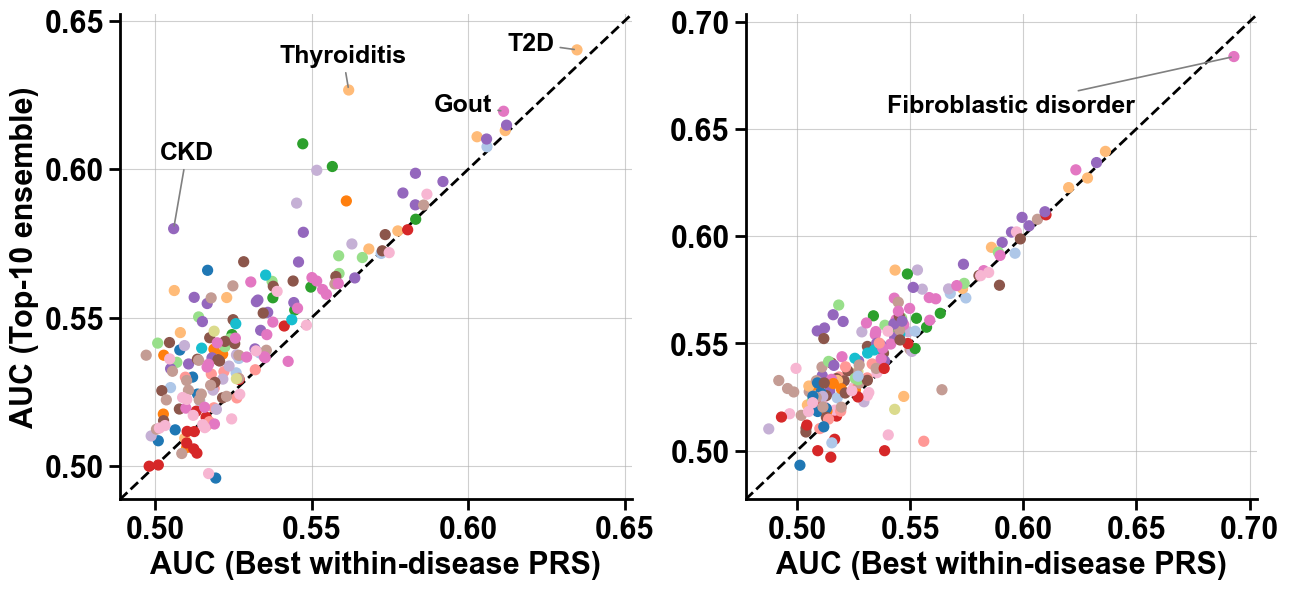

In [5]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['font.family'] = 'Arial'

# Column names in the overall results table (edit if different)
x_col = "best_target_single"
y_col = "glm"
x_label = "AUC (Best within-disease PRS)"
y_label = "AUC (Top-10 ensemble)"
pad_frac = 0.05
tick_step = 0.05  # tick spacing: all tick labels are multiples of 0.05

# Diseases to annotate per panel: ICD -> (display name, (dx, dy) label offset in points)
# Panel 0 = AoU, panel 1 = UKB; offsets are set separately because point positions differ between cohorts
panel_labels = {
    0: {
        "E11": ("T2D",  (-50, -0.03)),
        "M10": ("Gout", (-50,  0.01)),
        "E06": ("Thyroiditis", (-50,  20)),
        "I12": ("CKD",  (-10,  50)),
    },
    1: {
        "M72": ("Fibroblastic disorder", (-250, -40)),
    },
}

# Merge top-10 GLM / best within-disease results with all-PRS GLM results on ICD
aou_plot = aou_data[["icd", "roman", x_col, y_col]].merge(
    aou_allprs[["icd", "auc"]].rename(columns={"auc": "allprs_auc"}), on="icd", how="inner")
ukb_plot = ukb_data[["icd", "roman", x_col, y_col]].merge(
    ukb_allprs[["icd", "auc"]].rename(columns={"auc": "allprs_auc"}), on="icd", how="inner")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for i, sub in enumerate([aou_plot, ukb_plot]):
    ax = axes[i]

    # Adaptive square limits for this panel: data range of the two plotted columns plus padding
    vals = sub[[x_col, y_col]].values.ravel().astype(float)
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    pad = (vmax - vmin) * pad_frac
    lo, hi = vmin - pad, vmax + pad

    # AoU panel: extend the upper limit slightly so the 0.65 tick is shown
    if i == 0:
        hi = max(hi, 0.65 + pad * 0.3)

    # Ticks at multiples of 0.05 inside the limits (rounded to avoid floating-point drift)
    ticks = np.arange(np.ceil(lo / tick_step) * tick_step, hi + 1e-9, tick_step)
    ticks = np.round(ticks, 2)

    # Scatter: best within-disease PRS AUC (x) vs top-10 ensemble AUC (y), colored by ICD-10 chapter
    ax.scatter(sub[x_col], sub[y_col], color=sub["roman"].map(cm.roman2color_map), s=50, zorder=3)

    # y = x diagonal
    ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=2)

    # Annotate selected diseases with a name label and a gray leader line
    labels_here = panel_labels.get(i, {})
    to_label = sub[sub["icd"].isin(labels_here.keys())]
    for _, row in to_label.iterrows():
        name, (dx, dy) = labels_here[row["icd"]]
        ax.annotate(name,
                    xy=(row[x_col], row[y_col]),
                    xytext=(dx, dy), textcoords="offset points",
                    fontsize=18, fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
                    annotation_clip=False, zorder=4)

    # Axis limits, ticks, labels
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels([f"{t:.2f}" for t in ticks])
    ax.set_yticklabels([f"{t:.2f}" for t in ticks])
    ax.set_xlabel(x_label, fontsize=22, fontweight="bold")
    if i == 0:
        ax.set_ylabel(y_label, fontsize=22, fontweight="bold")

    # Spines, grid, ticks styling
    ax.grid(alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(axis="both", labelsize=22, length=8, width=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

plt.tight_layout()
plt.show()

In [6]:
# Compute AUC gain of top-10 ensemble over best within-disease PRS in AoU
aou_plot["delta"] = aou_plot[x_col] - aou_plot[y_col]

# List the diseases farthest above the y = x line (largest gains)
print(aou_plot.sort_values("delta", ascending=False)[["icd", "roman", x_col, y_col, "delta"]].head(10))

     icd roman  best_target_single       glm     delta
2    B02     I            0.519389  0.496011  0.023378
172  N92   XIV            0.517116  0.497528  0.019588
54   H43   VII            0.513396  0.504403  0.008993
170  N83   XIV            0.524481  0.515935  0.008546
145  M35  XIII            0.542521  0.535309  0.007212
57   H57   VII            0.512377  0.505832  0.006545
158  M94  XIII            0.518983  0.514219  0.004763
127  L60   XII            0.508557  0.504278  0.004279
19   D75   III            0.510127  0.506293  0.003834
62   H81  VIII            0.526129  0.523009  0.003120


# AUC Top10 Ensemble Vs All-PRS Ensemble

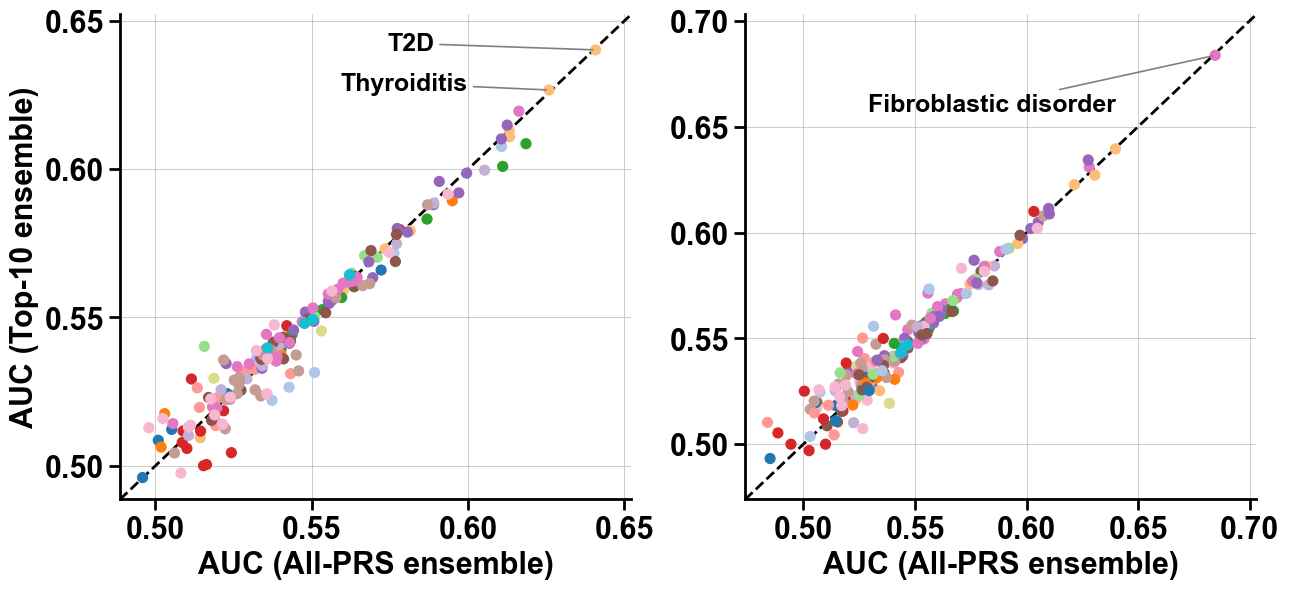

In [7]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['font.family'] = 'Arial'

# Column names in the overall results table (edit if different)
x_col = "all_prs"
y_col = "glm"
x_label = "AUC (All-PRS ensemble)"
y_label = "AUC (Top-10 ensemble)"
pad_frac = 0.05
tick_step = 0.05  # tick spacing: all tick labels are multiples of 0.05

# Diseases to annotate per panel: ICD -> (display name, (dx, dy) label offset in points)
# Panel 0 = AoU, panel 1 = UKB; offsets are set separately because point positions differ between cohorts
panel_labels = {
    0: {
        "E11": ("T2D",  (-150, -0.03)),
        "E06": ("Thyroiditis", (-150, -0.03)),
    },
    1: {
        "M72": ("Fibroblastic disorder", (-250, -40)),
    },
}

# Merge top-10 GLM / best single results with all-PRS GLM results on ICD
aou_plot = aou_data[["icd", "roman", x_col, y_col]].merge(
    aou_allprs[["icd", "auc"]].rename(columns={"auc": "allprs_auc"}), on="icd", how="inner")
ukb_plot = ukb_data[["icd", "roman", x_col, y_col]].merge(
    ukb_allprs[["icd", "auc"]].rename(columns={"auc": "allprs_auc"}), on="icd", how="inner")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for i, sub in enumerate([aou_plot, ukb_plot]):
    ax = axes[i]

    # Adaptive square limits for this panel: data range of the two plotted columns plus padding
    vals = sub[[x_col, y_col]].values.ravel().astype(float)
    vmin, vmax = np.nanmin(vals), np.nanmax(vals)
    pad = (vmax - vmin) * pad_frac
    lo, hi = vmin - pad, vmax + pad

    # Extend the upper limit to the next multiple of tick_step so the top tick is always shown
    hi = max(hi, np.ceil(vmax / tick_step) * tick_step + pad * 0.3)

    # Ticks at multiples of 0.05 inside the limits (rounded to avoid floating-point drift)
    ticks = np.arange(np.ceil(lo / tick_step) * tick_step, hi + 1e-9, tick_step)
    ticks = np.round(ticks, 2)

    # Scatter: all-PRS ensemble AUC (x) vs top-10 ensemble AUC (y), colored by ICD-10 chapter
    ax.scatter(sub[x_col], sub[y_col], color=sub["roman"].map(cm.roman2color_map), s=50, zorder=3)

    # y = x diagonal
    ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=2)

    # Annotate selected diseases with a name label and a gray leader line
    labels_here = panel_labels.get(i, {})
    to_label = sub[sub["icd"].isin(labels_here.keys())]
    for _, row in to_label.iterrows():
        name, (dx, dy) = labels_here[row["icd"]]
        ax.annotate(name,
                    xy=(row[x_col], row[y_col]),
                    xytext=(dx, dy), textcoords="offset points",
                    fontsize=18, fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
                    annotation_clip=False, zorder=4)

    # Axis limits, ticks, labels
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels([f"{t:.2f}" for t in ticks])
    ax.set_yticklabels([f"{t:.2f}" for t in ticks])
    ax.set_xlabel(x_label, fontsize=22, fontweight="bold")
    if i == 0:
        ax.set_ylabel(y_label, fontsize=22, fontweight="bold")

    # Spines, grid, ticks styling
    ax.grid(alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(axis="both", labelsize=22, length=8, width=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

plt.tight_layout()
plt.show()

In [8]:
# Compute AUC gain of top-10 ensemble over best within-disease PRS in AoU
aou_plot["delta"] = aou_plot[x_col] - aou_plot[y_col]

# List the diseases farthest above the y = x line (largest gains)
print(aou_plot.sort_values("delta", ascending=False)[["icd", "roman", x_col, y_col, "delta"]].head(10))

     icd roman   all_prs       glm     delta
54   H43   VII  0.524284  0.504403  0.019880
11   D22    II  0.550900  0.531446  0.019454
12   D23    II  0.542751  0.526481  0.016270
55   H52   VII  0.516313  0.500410  0.015902
50   H25   VII  0.515384  0.500000  0.015384
10   D18    II  0.537298  0.522042  0.015256
131  L81   XII  0.545785  0.531975  0.013810
61   H66  VIII  0.543234  0.531042  0.012192
165  N60   XIV  0.535652  0.524238  0.011413
172  N92   XIV  0.508138  0.497528  0.010611


# Prev Ratio

In [11]:
# ── Load data ──────────────────────────────────────────────────────────────
base = os.path.join(cm.ROOT_PATH, "result", "prev_ratio")

# List to collect all loaded dataframes
all_dfs = []
for cohort in ["aou", "ukb"]:
    for case in ["ensemble", "bestsingle", "targetsingle", "allprs_ensemble"]:
        filepath = os.path.join(base, f"{cohort}_{case}_stratified_disease_rate.csv")
        data = pd.read_csv(filepath)
        
        # Add identifier columns for cohort and case type
        data["cohort"] = cohort
        data["case"] = case
        
        all_dfs.append(data)

# Concatenate all dataframes into one
combined = pd.concat(all_dfs, ignore_index=True)

# filter reported trait
report_trait = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "ukb_ensembleprs_overall_overlaptraits.csv"))
report_trait = report_trait[report_trait["ensemble_case_num"] > 2000]
combined = combined[combined["icd"].isin(report_trait["icd"])]
print("Traits available:", len(combined["icd"].unique()))

Traits available: 181


In [12]:
prev_df = (
    combined.groupby(["icd", "cohort", "case", "prs_group"], as_index=False)
      .agg(
          n_group_total=("n_group_total", "sum"),
          n_case=("n_case", "sum"),
      )
)
prev_df["prev_rate"] = prev_df["n_case"] / prev_df["n_group_total"]
prev_df["chapter"] = prev_df["icd"].apply(cm.assign_chapter)
prev_df["chapter_roman"] = prev_df["chapter"].map(cm.chapter2roman_map)

In [13]:
ratio_df = (
    prev_df
    .pivot(
        index=["icd", "cohort", "case"],
        columns="prs_group",
        values="prev_rate"
    )
    .reset_index()
)

ratio_df["top_bottom_ratio"] = ratio_df["Top 10%"] / ratio_df["Bottom 10%"]
ratio_df["chapter"] = ratio_df["icd"].apply(cm.assign_chapter)
ratio_df["chapter_roman"] = ratio_df["chapter"].map(cm.chapter2roman_map)

# Ensemble Vs Single Prev Ratio

In [14]:
# pivot dataframe to icd - ensemble, cross single, target single 
plot_ratio = (
    ratio_df
    .pivot_table(
        index=["icd", "cohort", "chapter", "chapter_roman"],
        columns="case",
        values="top_bottom_ratio"
    )
    .reset_index()
)

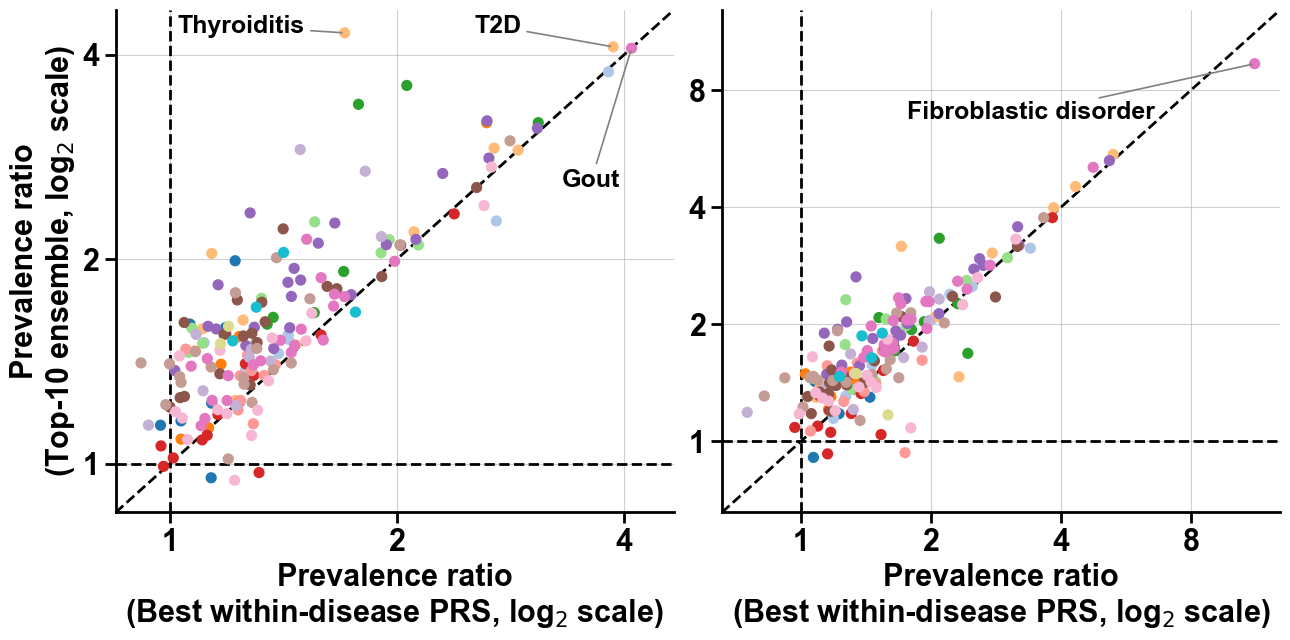

In [15]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['font.family'] = 'Arial'

# Column names in plot_ratio (edit if different)
x_col = "targetsingle"
y_col = "ensemble"
x_label = "Prevalence ratio\n(Best within-disease PRS, log$_2$ scale)"
y_label = "Prevalence ratio\n(Top-10 ensemble, log$_2$ scale)"
win_label = "Top-10 > Best within"
pad_frac = 0.05

# Diseases to annotate per cohort: ICD -> (display name, (dx, dy) label offset in points)
labels_to_add = {
    "aou": {
        "E11": ("T2D",  (-100, 10)),
        "M10": ("Gout", (-50, -100)),
        "E06": ("Thyroiditis", (-120,  0)),
    },
    "ukb": {
        "M72": ("Fibroblastic disorder", (-250, -40)),
    },
}
# Split by cohort
aou_plot = plot_ratio[plot_ratio["cohort"] == "aou"]
ukb_plot = plot_ratio[plot_ratio["cohort"] == "ukb"]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))

for i, (cohort, sub) in enumerate([("aou", aou_plot), ("ukb", ukb_plot)]):
    ax = axes[i]

    # Adaptive square limits in log2 space: positive finite range of the two plotted columns plus padding
    vals = sub[[x_col, y_col]].values.ravel().astype(float)
    vals = vals[np.isfinite(vals) & (vals > 0)]
    log_min, log_max = np.log2(vals.min()), np.log2(vals.max())
    pad = (log_max - log_min) * pad_frac
    lo, hi = 2.0 ** (log_min - pad), 2.0 ** (log_max + pad)

    # Ticks at integer powers of 2 within the limits, shared by both axes
    ticks = 2.0 ** np.arange(np.ceil(np.log2(lo)), np.floor(np.log2(hi)) + 1)
    tick_labels = [f"{t:g}" for t in ticks]

    # Scatter: best within-disease PRS (x) vs top-10 ensemble (y) prevalence ratio, colored by ICD-10 chapter
    ax.scatter(sub[x_col], sub[y_col], color=sub["chapter"].map(cm.chapter2color_map), s=50, zorder=3)

    # y = x diagonal and reference lines at prevalence ratio = 1
    ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=2)
    ax.axvline(1, color="black", linestyle="--", linewidth=2)
    ax.axhline(1, color="black", linestyle="--", linewidth=2)

    # Annotate selected diseases; offsets are in points so they behave the same on a log axis
    to_label = sub[sub["icd"].isin(labels_to_add[cohort].keys())]
    for _, row in to_label.iterrows():
        name, (dx, dy) = labels_to_add[cohort][row["icd"]]
        ax.annotate(name,
                    xy=(row[x_col], row[y_col]),
                    xytext=(dx, dy), textcoords="offset points",
                    fontsize=18, fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
                    annotation_clip=False)

    # Percentage of diseases above y = x (top-10 ensemble > best within-disease PRS)
    # n = sub[[x_col, y_col]].dropna().shape[0]
    # pct_win = (sub[y_col] > sub[x_col]).sum() / n * 100
    # ax.text(0.03, 0.97, f"{win_label}: {pct_win:.1f}%",
    #         transform=ax.transAxes, ha="left", va="top", fontsize=16, fontweight="bold")

    # Log-scale axes (base 2) with plain-number tick labels and no minor ticks
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(tick_labels)
    ax.set_yticklabels(tick_labels)
    ax.minorticks_off()
    ax.set_xlabel(x_label, fontsize=22, fontweight="bold")
    if i == 0:
        ax.set_ylabel(y_label, fontsize=22, fontweight="bold")

    # Spines, grid, ticks styling
    ax.grid(alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(axis="both", labelsize=22, length=8, width=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

plt.tight_layout()
plt.show()

# Ensemble Vs All-PRS Ensemble

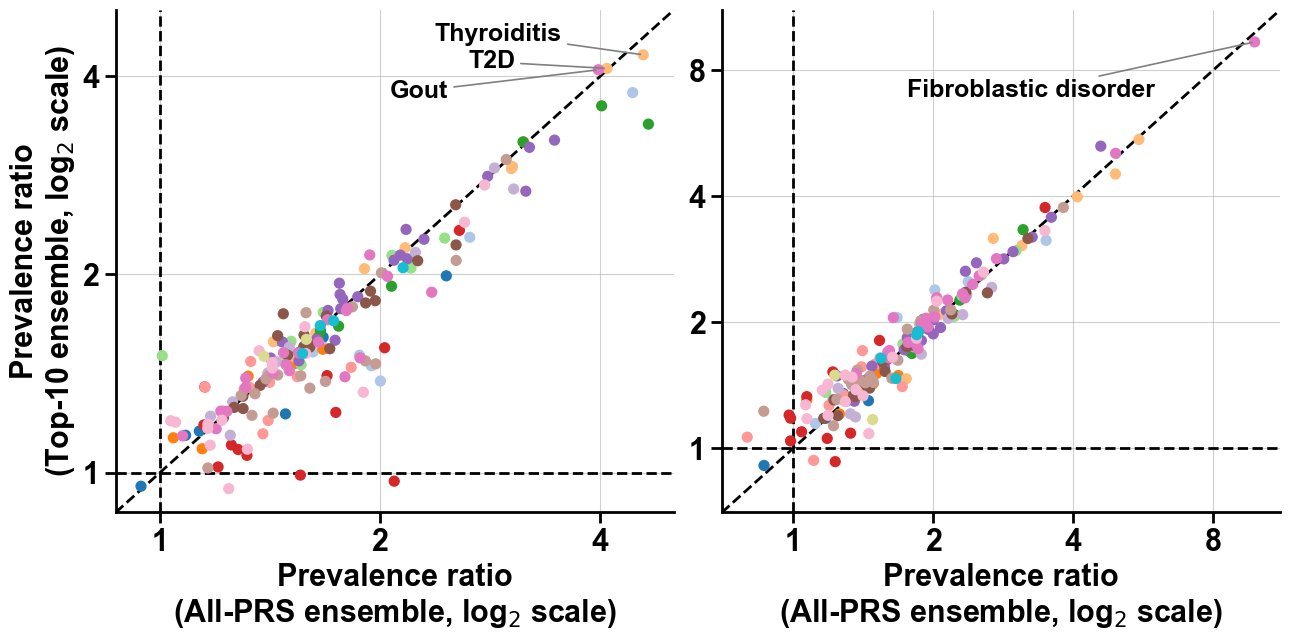

In [16]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['font.family'] = 'Arial'

# Column names in plot_ratio (edit if different)
x_col = "allprs_ensemble"
y_col = "ensemble"
x_label = "Prevalence ratio\n(All-PRS ensemble, log$_2$ scale)"
y_label = "Prevalence ratio\n(Top-10 ensemble, log$_2$ scale)"
win_label = "Top-10 > All-PRS"
pad_frac = 0.05

# Diseases to annotate per cohort: ICD -> (display name, (dx, dy) label offset in points)
labels_to_add = {
    "aou": {
        "E11": ("T2D",  (-100, 0)),
        "M10": ("Gout", (-150, -20)),
        "E06": ("Thyroiditis", (-150, 10)),
    },
    "ukb": {
        "M72": ("Fibroblastic disorder", (-250, -40)),
    },
}
# Split by cohort
aou_plot = plot_ratio[plot_ratio["cohort"] == "aou"]
ukb_plot = plot_ratio[plot_ratio["cohort"] == "ukb"]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))

for i, (cohort, sub) in enumerate([("aou", aou_plot), ("ukb", ukb_plot)]):
    ax = axes[i]

    # Adaptive square limits in log2 space: positive finite range of the two plotted columns plus padding
    vals = sub[[x_col, y_col]].values.ravel().astype(float)
    vals = vals[np.isfinite(vals) & (vals > 0)]
    log_min, log_max = np.log2(vals.min()), np.log2(vals.max())
    pad = (log_max - log_min) * pad_frac
    lo, hi = 2.0 ** (log_min - pad), 2.0 ** (log_max + pad)

    # Ticks at integer powers of 2 within the limits, shared by both axes
    ticks = 2.0 ** np.arange(np.ceil(np.log2(lo)), np.floor(np.log2(hi)) + 1)
    tick_labels = [f"{t:g}" for t in ticks]

    # Scatter: all-PRS ensemble (x) vs top-10 ensemble (y) prevalence ratio, colored by ICD-10 chapter
    ax.scatter(sub[x_col], sub[y_col], color=sub["chapter"].map(cm.chapter2color_map), s=50, zorder=3)

    # y = x diagonal and reference lines at prevalence ratio = 1
    ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=2)
    ax.axvline(1, color="black", linestyle="--", linewidth=2)
    ax.axhline(1, color="black", linestyle="--", linewidth=2)

    # Annotate selected diseases; offsets are in points so they behave the same on a log axis
    to_label = sub[sub["icd"].isin(labels_to_add[cohort].keys())]
    for _, row in to_label.iterrows():
        name, (dx, dy) = labels_to_add[cohort][row["icd"]]
        ax.annotate(name,
                    xy=(row[x_col], row[y_col]),
                    xytext=(dx, dy), textcoords="offset points",
                    fontsize=18, fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
                    annotation_clip=False)

    # Percentage of diseases above y = x (top-10 ensemble > all-PRS ensemble)
    # n = sub[[x_col, y_col]].dropna().shape[0]
    # pct_win = (sub[y_col] > sub[x_col]).sum() / n * 100
    # ax.text(0.03, 0.97, f"{win_label}: {pct_win:.1f}%",
    #         transform=ax.transAxes, ha="left", va="top", fontsize=16, fontweight="bold")

    # Log-scale axes (base 2) with plain-number tick labels and no minor ticks
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(tick_labels)
    ax.set_yticklabels(tick_labels)
    ax.minorticks_off()
    ax.set_xlabel(x_label, fontsize=22, fontweight="bold")
    if i == 0:
        ax.set_ylabel(y_label, fontsize=22, fontweight="bold")

    # Spines, grid, ticks styling
    ax.grid(alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(axis="both", labelsize=22, length=8, width=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

plt.tight_layout()
plt.show()

# Rrev Ratio and AUC transferability

In [18]:
# Read AUC Transferability #
aou_data = pd.read_csv(
    os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "aou_ensembleprs_overall_overlaptraits.csv"))
ukb_data = pd.read_csv(
    os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "ukb_ensembleprs_overall_overlaptraits.csv"))

# filter Num of Training Case > 2000
aou_data = aou_data[aou_data["ensemble_case_num"] > 2000]
ukb_data = ukb_data[ukb_data["ensemble_case_num"] > 2000]

aou_data = aou_data[['icd', 'glm']].rename(columns={"glm": "aou_glm"})
ukb_data = ukb_data[['icd', 'glm']].rename(columns={"glm": "ukb_glm"})
auc_transferability = aou_data.merge(ukb_data, on="icd")
auc_transferability["chapter"] = auc_transferability["icd"].apply(cm.assign_chapter)
auc_transferability["roman"] = auc_transferability["chapter"].map(cm.chapter2roman_map)
print("Traits available:", len(auc_transferability["icd"].unique()))

Traits available: 181


In [19]:
# Convert Prev Ratio Transferability #
plot_ratio["color"] = plot_ratio["chapter"].map(cm.chapter2color_map)
aou_data = plot_ratio[plot_ratio["cohort"] == "aou"][["icd", "chapter", "color", "ensemble"]].rename(columns={"ensemble": "aou"})
ukb_data = plot_ratio[plot_ratio["cohort"] == "ukb"][["icd", "ensemble"]].rename(columns={"ensemble": "ukb"})
prev_transferability = aou_data.merge(ukb_data, on="icd")
print("Traits available:", len(prev_transferability["icd"].unique()))

Traits available: 181


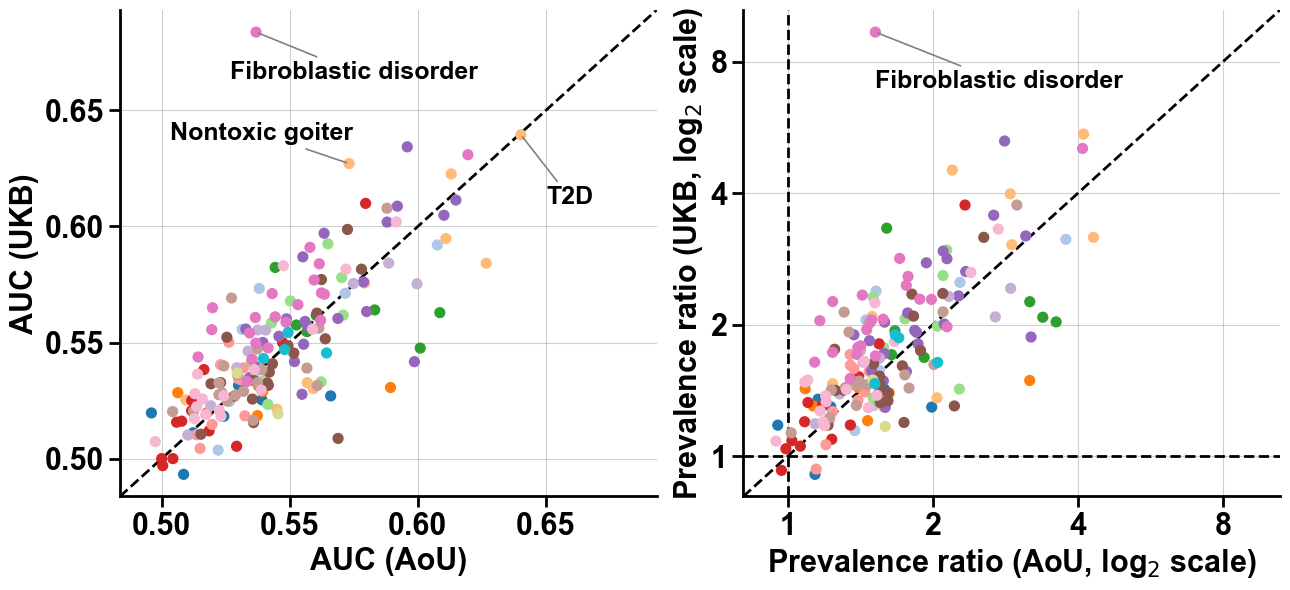

In [20]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

matplotlib.rcParams['font.family'] = 'Arial'

pad_frac = 0.05

# AUC panel: ICD -> (display name, (dx, dy) label offset in data units on the linear axis)
auc_labels = {
    "E04": ("Nontoxic goiter", (-0.07, 0.01)),
    "E11": ("T2D", (0.01, -0.03)),
    "M72": ("Fibroblastic disorder", (-0.01, -0.02)),
}

# Prevalence ratio panel: ICD -> (display name, (dx, dy) label offset in points on the log axis)
prev_labels = {
    "F20": ("Schizophrenia", (-130, -40)),
    "M72": ("Fibroblastic disorder", (-0.01, -40)),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))


### AUC transferability (linear axes) ###

ax = axes[0]
x_col, y_col = "aou_glm", "ukb_glm"

# Adaptive square limits: data range of both cohorts plus padding
vals = auc_transferability[[x_col, y_col]].values.ravel().astype(float)
vals = vals[np.isfinite(vals)]
pad = (vals.max() - vals.min()) * pad_frac
lo, hi = vals.min() - pad, vals.max() + pad

# Auto-chosen round ticks within the limits, shared by both axes
ticks = MaxNLocator(nbins=5).tick_values(lo, hi)
ticks = ticks[(ticks >= lo) & (ticks <= hi)]

# Scatter: AoU AUC (x) vs UKB AUC (y), colored by ICD-10 chapter
ax.scatter(auc_transferability[x_col], auc_transferability[y_col],
           color=auc_transferability["chapter"].map(cm.chapter2color_map).fillna("gray"),
           s=50, zorder=3)

# y = x diagonal
ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=2)

# Annotate selected diseases with a name label and a gray leader line
to_label = auc_transferability[auc_transferability["icd"].isin(auc_labels.keys())]
for _, row in to_label.iterrows():
    name, (dx, dy) = auc_labels[row["icd"]]
    ax.annotate(name,
                xy=(row[x_col], row[y_col]),
                xytext=(row[x_col] + dx, row[y_col] + dy),
                fontsize=18, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
                annotation_clip=False)

# Axis limits, ticks, labels
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels([f"{t:.2f}" for t in ticks])
ax.set_yticklabels([f"{t:.2f}" for t in ticks])
ax.set_xlabel("AUC (AoU)", fontsize=22, fontweight="bold")
ax.set_ylabel("AUC (UKB)", fontsize=22, fontweight="bold")


### Prevalence ratio transferability (log2 axes) ###

ax = axes[1]
x_col, y_col = "aou", "ukb"

# Adaptive square limits in log2 space: positive finite range of both cohorts plus padding
vals = prev_transferability[[x_col, y_col]].values.ravel().astype(float)
vals = vals[np.isfinite(vals) & (vals > 0)]
log_min, log_max = np.log2(vals.min()), np.log2(vals.max())
pad = (log_max - log_min) * pad_frac
lo, hi = 2.0 ** (log_min - pad), 2.0 ** (log_max + pad)

# Ticks at integer powers of 2 within the limits, shared by both axes
ticks = 2.0 ** np.arange(np.ceil(np.log2(lo)), np.floor(np.log2(hi)) + 1)
tick_labels = [f"{t:g}" for t in ticks]

# Scatter: AoU prevalence ratio (x) vs UKB prevalence ratio (y), colored by ICD-10 chapter
ax.scatter(prev_transferability[x_col], prev_transferability[y_col],
           color=prev_transferability["chapter"].map(cm.chapter2color_map).fillna("gray"),
           s=50, zorder=3)

# y = x diagonal and reference lines at prevalence ratio = 1
ax.plot([lo, hi], [lo, hi], color="black", linestyle="--", linewidth=2)
ax.axvline(1, color="black", linestyle="--", linewidth=2)
ax.axhline(1, color="black", linestyle="--", linewidth=2)

# Annotate selected diseases; offsets are in points so they behave the same on a log axis
to_label = prev_transferability[prev_transferability["icd"].isin(prev_labels.keys())]
for _, row in to_label.iterrows():
    name, (dx, dy) = prev_labels[row["icd"]]
    ax.annotate(name,
                xy=(row[x_col], row[y_col]),
                xytext=(dx, dy), textcoords="offset points",
                fontsize=18, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
                annotation_clip=False)

# Log-scale axes (base 2) with plain-number tick labels and no minor ticks
ax.set_xscale("log", base=2)
ax.set_yscale("log", base=2)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(tick_labels)
ax.set_yticklabels(tick_labels)
ax.minorticks_off()
ax.set_xlabel("Prevalence ratio (AoU, log$_2$ scale)", fontsize=22, fontweight="bold")
ax.set_ylabel("Prevalence ratio (UKB, log$_2$ scale)", fontsize=22, fontweight="bold")


### Shared styling ###

for ax in axes:
    ax.grid(alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(axis="both", labelsize=22, length=8, width=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

plt.tight_layout()
plt.show()

# anchors

In [22]:
# Statistics for the revised ensemble section (Fig. 5, >2,000-case diseases)
# Run in 22.Ensemble_PRS_evaluation_4.ipynb AFTER cell 15 (needs `plot_ratio`).
# AUC tables are reloaded here because later cells overwrite `aou_data` / `ukb_data`.

import os
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
import common as cm

# ---------------------------------------------------------------------------
# Settings
# ---------------------------------------------------------------------------
base_col = "best_target_single"            # baseline in Fig. 5a: best within-disease PRS
methods = ["glm", "superlearner", "autogluon", "tabpfn"]
min_cases = 2000                           # same filter as the Fig. 5 cells (> 2,000 training cases)
gain_cut = 0.10                            # 10% relative-gain threshold

# ---------------------------------------------------------------------------
# Load AUC tables, apply the >2,000-case filter, add the all-PRS ensemble AUC
# ---------------------------------------------------------------------------
aou = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "aou_ensembleprs_overall_overlaptraits.csv"))
ukb = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "ensembleprs", "ukb_ensembleprs_overall_overlaptraits.csv"))
aou = aou[aou["ensemble_case_num"] > min_cases].copy()
ukb = ukb[ukb["ensemble_case_num"] > min_cases].copy()

aou_allprs = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "increase_prs_num", "aou_glm_allprs_result.csv"))
ukb_allprs = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "increase_prs_num", "ukb_glm_allprs_result.csv"))

# Drop any existing all-PRS column, then merge the all-PRS ensemble AUC as "all_prs"
aou = aou.drop(columns=["all_prs"], errors="ignore").merge(
    aou_allprs[["icd", "auc"]].rename(columns={"auc": "all_prs"}), on="icd", how="left")
ukb = ukb.drop(columns=["all_prs"], errors="ignore").merge(
    ukb_allprs[["icd", "auc"]].rename(columns={"auc": "all_prs"}), on="icd", how="left")

# One wide table: <column>_aou and <column>_ukb for every disease present in both cohorts
keep_cols = ["icd", base_col, "all_prs"] + methods
df = aou[keep_cols].merge(ukb[keep_cols], on="icd", suffixes=("_aou", "_ukb"))
df["chapter"] = df["icd"].apply(cm.assign_chapter)
print("Diseases in analysis:", len(df))

# Relative gain over the baseline, on the excess-over-0.5 scale: (AUC_ens - 0.5) / (AUC_base - 0.5) - 1
# NOTE: replace with the definition used in the original analysis if it differed
# Undefined (NaN) when the baseline AUC <= 0.5
for c in ["aou", "ukb"]:
    base_excess = (df[f"{base_col}_{c}"] - 0.5).where(df[f"{base_col}_{c}"] > 0.5)
    for m in methods + ["all_prs"]:
        df[f"rel_{m}_{c}"] = (df[f"{m}_{c}"] - 0.5) / base_excess - 1
        df[f"delta_{m}_{c}"] = df[f"{m}_{c}"] - df[f"{base_col}_{c}"]

# ---------------------------------------------------------------------------
# Paragraph 1: top-10 GLM ensemble vs best within-disease PRS
# ---------------------------------------------------------------------------
print("\n=== P1: top-10 GLM vs best within-disease PRS ===")
for c in ["aou", "ukb"]:
    win = df[f"glm_{c}"] > df[f"{base_col}_{c}"]
    p = stats.wilcoxon(df[f"glm_{c}"], df[f"{base_col}_{c}"]).pvalue
    print(f"{c}: win = {win.mean() * 100:.1f}% ({win.sum()}/{len(df)}), Wilcoxon P = {p:.2e}")
    print(f"{c}: relative gain mean = {df[f'rel_glm_{c}'].mean() * 100:.1f}%, median = {df[f'rel_glm_{c}'].median() * 100:.1f}%")
    losses = df.loc[~win, f"delta_glm_{c}"]
    print(f"{c}: n losses = {len(losses)}, median dAUC among losses = {losses.median():.3f}, worst = {losses.min():.3f}")

both = (df["glm_aou"] > df[f"{base_col}_aou"]) & (df["glm_ukb"] > df[f"{base_col}_ukb"])
print(f"Improved in both cohorts: {both.mean() * 100:.1f}% ({both.sum()}/{len(df)})")

# Largest absolute gains (sorted by AoU dAUC), with UKB values alongside
print("\nLargest AoU gains:")
print(df.sort_values("delta_glm_aou", ascending=False)[["icd", "chapter", "delta_glm_aou", "delta_glm_ukb"]].head(10).round(3))
print("\nLargest UKB gains:")
print(df.sort_values("delta_glm_ukb", ascending=False)[["icd", "chapter", "delta_glm_aou", "delta_glm_ukb"]].head(10).round(3))

# Diseases labeled in Fig. 5a / 5d
labeled = ["E06", "I12", "E11", "M10", "M72", "E04"]
print("\nLabeled diseases (AUC):")
print(df[df["icd"].isin(labeled)][["icd", f"{base_col}_aou", "glm_aou", "all_prs_aou",
                                   f"{base_col}_ukb", "glm_ukb", "all_prs_ukb"]].round(3))

# ---------------------------------------------------------------------------
# Paragraph 2: top-10 vs all-PRS ensemble
# ---------------------------------------------------------------------------
print("\n=== P2: top-10 vs all-PRS ensemble ===")
for c in ["aou", "ukb"]:
    top_vs_all = (df[f"glm_{c}"] > df[f"all_prs_{c}"]).mean() * 100
    p = stats.wilcoxon(df[f"glm_{c}"], df[f"all_prs_{c}"]).pvalue
    top_vs_base = (df[f"glm_{c}"] > df[f"{base_col}_{c}"]).mean() * 100
    all_vs_base = (df[f"all_prs_{c}"] > df[f"{base_col}_{c}"]).mean() * 100
    print(f"{c}: top-10 > all-PRS = {top_vs_all:.1f}% (Wilcoxon P = {p:.2e}); "
          f"top-10 > base = {top_vs_base:.1f}%; all-PRS > base = {all_vs_base:.1f}%")

# ---------------------------------------------------------------------------
# Paragraph 3: framework comparison
# ---------------------------------------------------------------------------
print("\n=== P3a: Spearman correlation of GLM with other frameworks ===")
for c in ["aou", "ukb"]:
    for m in ["superlearner", "tabpfn", "autogluon"]:
        r, p = stats.spearmanr(df[f"glm_{c}"], df[f"{m}_{c}"])
        print(f"{c}: GLM vs {m}: r = {r:.3f}, P = {p:.1e}")

print("\n=== P3b: AoU-UKB Pearson concordance ===")
for m in [base_col] + methods:
    r, p = stats.pearsonr(df[f"{m}_aou"], df[f"{m}_ukb"])
    print(f"{m}: r = {r:.2f}, P = {p:.1e}")

print("\n=== P3c: UKB AUC < 0.5 (exact McNemar vs baseline) ===")
base_fail = df[f"{base_col}_ukb"] < 0.5
print(f"baseline: {base_fail.sum()} ({base_fail.mean() * 100:.1f}%), min UKB AUC = {df[f'{base_col}_ukb'].min():.3f}")
for m in methods:
    m_fail = df[f"{m}_ukb"] < 0.5
    table = [[(base_fail & m_fail).sum(), (base_fail & ~m_fail).sum()],
             [(~base_fail & m_fail).sum(), (~base_fail & ~m_fail).sum()]]
    p = mcnemar(table, exact=True).pvalue
    print(f"{m}: {m_fail.sum()} ({m_fail.mean() * 100:.1f}%), McNemar P = {p:.1e}, min UKB AUC = {df[f'{m}_ukb'].min():.3f}")

print("\n=== P3d: >10% relative gain in both cohorts ===")
big_sets = {}
for m in methods:
    big = (df[f"rel_{m}_aou"] > gain_cut) & (df[f"rel_{m}_ukb"] > gain_cut)
    big_sets[m] = set(df.loc[big, "icd"])
    print(f"{m}: {big.sum()}")

# Best framework per disease, chosen by AoU AUC, then checked in both cohorts
best_m = df[[f"{m}_aou" for m in methods]].idxmax(axis=1).str.replace("_aou", "", regex=False)
rel_best_aou = np.array([df.loc[i, f"rel_{best_m[i]}_aou"] for i in df.index])
rel_best_ukb = np.array([df.loc[i, f"rel_{best_m[i]}_ukb"] for i in df.index])
print(f"best framework per disease (selected in AoU): {((rel_best_aou > gain_cut) & (rel_best_ukb > gain_cut)).sum()}")

# Diseases passing under all four frameworks, with chapter counts
all_four = set.intersection(*big_sets.values())
print(f"all four frameworks: {len(all_four)} ({len(all_four) / len(df) * 100:.1f}%)")
print(df[df["icd"].isin(all_four)]["chapter"].value_counts())
print(sorted(all_four))

print("\n=== P3e: poor transfer (>10% gain in AoU, loss in UKB) ===")
poor_count = pd.Series(0, index=df["icd"])
for m in methods:
    poor = (df[f"rel_{m}_aou"] > gain_cut) & (df[f"{m}_ukb"] < df[f"{base_col}_ukb"])
    poor_count[df.loc[poor, "icd"]] += 1
    print(f"{m}: {poor.sum()}")
print("Poor transfer under >= 2 frameworks:", sorted(poor_count[poor_count >= 2].index))
print(df[df["icd"].isin(poor_count[poor_count >= 2].index)]["chapter"].value_counts())

# ---------------------------------------------------------------------------
# Paragraph 4: risk stratification (prevalence ratio, from `plot_ratio`)
# ---------------------------------------------------------------------------
print("\n=== P4: prevalence ratio ===")
pr_aou = plot_ratio[plot_ratio["cohort"] == "aou"].set_index("icd")
pr_ukb = plot_ratio[plot_ratio["cohort"] == "ukb"].set_index("icd")

for c, pr in [("aou", pr_aou), ("ukb", pr_ukb)]:
    for comp in ["targetsingle", "allprs_ensemble"]:
        sub = pr[["ensemble", comp]].replace([np.inf, -np.inf], np.nan).dropna()
        higher = (sub["ensemble"] > sub[comp]).mean() * 100
        p = stats.wilcoxon(sub["ensemble"], sub[comp]).pvalue
        print(f"{c}: ensemble vs {comp}: median {sub['ensemble'].median():.2f} vs {sub[comp].median():.2f}, "
              f"higher = {higher:.1f}% (n = {len(sub)}), Wilcoxon P = {p:.1e}")

# Largest stratification gains over the best within-disease PRS (ratio of prevalence ratios)
for c, pr in [("aou", pr_aou), ("ukb", pr_ukb)]:
    tmp = pr[["chapter", "ensemble", "targetsingle"]].copy()
    tmp["fold"] = tmp["ensemble"] / tmp["targetsingle"]
    print(f"\nLargest stratification gains in {c}:")
    print(tmp.sort_values("fold", ascending=False).head(8).round(2))

# Cross-cohort concordance of the ensemble prevalence ratio (Fig. 5d right)
pr_both = pr_aou[["ensemble"]].join(pr_ukb[["ensemble"]], lsuffix="_aou", rsuffix="_ukb").dropna()
r, p = stats.spearmanr(pr_both["ensemble_aou"], pr_both["ensemble_ukb"])
print(f"\nAoU-UKB Spearman r (ensemble PR) = {r:.2f}, P = {p:.1e}, n = {len(pr_both)}")

# Diseases with the largest attenuation from AoU to UKB, and the labeled outlier M72
pr_both["ukb_over_aou"] = pr_both["ensemble_ukb"] / pr_both["ensemble_aou"]
print(pr_both.sort_values("ukb_over_aou").head(5).round(2))
print(pr_both.loc[pr_both.index.isin(["M72", "F20"])].round(2))

Diseases in analysis: 181

=== P1: top-10 GLM vs best within-disease PRS ===
aou: win = 85.1% (154/181), Wilcoxon P = 9.31e-25
aou: relative gain mean = 153.7%, median = 42.0%
aou: n losses = 27, median dAUC among losses = -0.003, worst = -0.023
ukb: win = 83.4% (151/181), Wilcoxon P = 4.68e-18
ukb: relative gain mean = 59.5%, median = 24.2%
ukb: n losses = 30, median dAUC among losses = -0.005, worst = -0.052
Improved in both cohorts: 75.7% (137/181)

Largest AoU gains:
    icd                  chapter  delta_glm_aou  delta_glm_ukb
68  I12     Circulatory diseases          0.074          0.047
22  E06       Metabolic diseases          0.065          0.041
31  F17         Mental disorders          0.061          0.029
28  E86       Metabolic diseases          0.053          0.025
0   A41      Infectious diseases          0.049          0.017
97  J44     Respiratory diseases          0.048          0.020
72  I27     Circulatory diseases          0.044          0.045
32  F31         Ment